In [4]:
# Install dependencies
%pip install kaggle tensorflow matplotlib opencv-python lxml

  Using cached kaggle-2.2.4-py3-none-any.whl.metadata (17 kB)
  Using cached jupytext-1.19.5-py3-none-any.whl.metadata (15 kB)
  Using cached kagglesdk-0.1.37-py3-none-any.whl.metadata (13 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached namex-0.1.0-py3-none-any.whl.metadata (322 bytes)
Using cached kaggle-2.2.4-py3-none-any.whl (126 kB)
Using cached kagglesdk-0.1.37-py3-none-any.whl (262 kB)
   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
  

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress t

In [1]:
import os
import zipfile
import shutil
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import xml.etree.ElementTree as ET

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = (128, 128)
CLASS_NAMES = ["trafficlight", "stop", "other"]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}

print("TensorFlow version:", tf.__version__)
print("Classes:", CLASS_NAMES)


TensorFlow version: 2.21.0
Classes: ['trafficlight', 'stop', 'other']


In [2]:
# Kaggle API setup
kaggle_dir = os.path.join(os.path.expanduser("~"), ".kaggle")
os.makedirs(kaggle_dir, exist_ok=True)

kaggle_key = "kaggle.json"
if os.path.exists(kaggle_key):
    shutil.copy(kaggle_key, os.path.join(kaggle_dir, "kaggle.json"))
    try:
        os.chmod(os.path.join(kaggle_dir, "kaggle.json"), 0o600)
    except OSError:
        pass
    print("Kaggle API key configured.")
else:
    print("kaggle.json not found. Add it to the notebook working directory before downloading the dataset.")


kaggle.json not found. Add it to the notebook working directory before downloading the dataset.


In [3]:
# Download and extract the dataset
import kaggle

data_dir = "./data"
zip_path = os.path.join(data_dir, "road-sign-detection.zip")
extract_dir = os.path.join(data_dir, "road-sign-detection")

os.makedirs(data_dir, exist_ok=True)

if not os.path.exists(extract_dir):
    !kaggle datasets download -d andrewmvd/road-sign-detection -p ./data --force
    os.makedirs(extract_dir, exist_ok=True)
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_dir)
    print("Dataset downloaded and extracted.")
else:
    print("Dataset already exists:", extract_dir)


Authentication required to call the Kaggle API.

First, you will need a Kaggle account. You can sign up at
  https://www.kaggle.com/account/login

Recommended: log in with OAuth via a web-based authorization flow.
No token to manage; credentials are cached locally for you.
    kaggle auth login

If you'd rather not use OAuth, generate an API token at
  https://www.kaggle.com/settings/api  (click "Generate New Token" under "API")
and supply it to the CLI in one of these ways:

  Option A: Environment variable
    export KAGGLE_API_TOKEN=xxxxxxxxxxxxxx  # token copied from the settings UI

  Option B: API token file
    Save the token to ~/.kaggle/access_token
Dataset URL: https://www.kaggle.com/datasets/andrewmvd/road-sign-detection
License(s): CC0-1.0




  0%|          | 0.00/218M [00:00<?, ?B/s]
  0%|          | 1.00M/218M [00:01<05:26, 697kB/s]
  1%|          | 2.00M/218M [00:01<02:43, 1.39MB/s]
  1%|▏         | 3.00M/218M [00:01<01:41, 2.23MB/s]
  2%|▏         | 4.00M/218M [00:02<01:21, 2.77MB/s]
  3%|▎         | 6.00M/218M [00:02<01:04, 3.47MB/s]
  3%|▎         | 7.00M/218M [00:02<00:54, 4.08MB/s]
  4%|▎         | 8.00M/218M [00:02<00:46, 4.72MB/s]
  4%|▍         | 9.00M/218M [00:02<00:42, 5.20MB/s]
  5%|▍         | 10.0M/218M [00:03<00:46, 4.67MB/s]
  5%|▌         | 11.0M/218M [00:03<00:41, 5.19MB/s]
  6%|▌         | 12.0M/218M [00:03<00:45, 4.78MB/s]
  6%|▌         | 13.0M/218M [00:03<00:44, 4.89MB/s]
  6%|▋         | 14.0M/218M [00:04<00:42, 5.05MB/s]
  7%|▋         | 15.0M/218M [00:04<00:40, 5.21MB/s]
  7%|▋         | 16.0M/218M [00:04<00:41, 5.10MB/s]
  8%|▊         | 17.0M/218M [00:04<00:40, 5.18MB/s]
  9%|▊         | 19.0M/218M [00:04<00:30, 6.83MB/s]
  9%|▉         | 20.0M/218M [00:05<00:29, 7.09MB/s]
 10%|▉         | 21.0

Dataset downloaded and extracted.


In [4]:
img_dir = os.path.join(extract_dir, "images")
ann_dir = os.path.join(extract_dir, "annotations")

print("Images:", len(os.listdir(img_dir)))
print("Annotations:", len(os.listdir(ann_dir)))


Images: 877
Annotations: 877


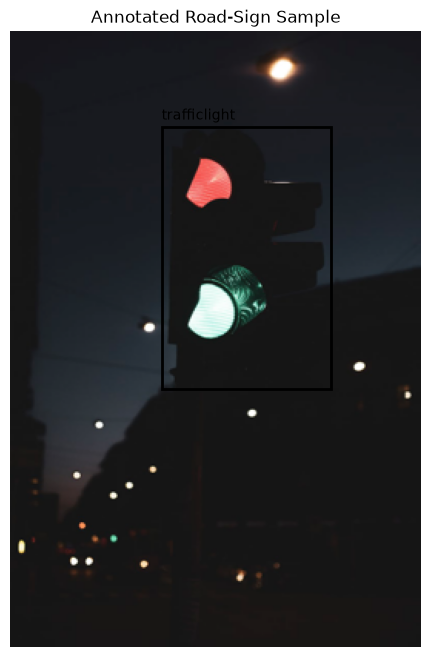

In [5]:
image_files = [
    f for f in os.listdir(img_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

sample_file = image_files[0]
sample_image_path = os.path.join(img_dir, sample_file)
sample_ann_path = os.path.join(ann_dir, os.path.splitext(sample_file)[0] + ".xml")

image = cv2.imread(sample_image_path)
if image is None:
    raise ValueError(f"Could not read image: {sample_image_path}")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
tree = ET.parse(sample_ann_path)
root = tree.getroot()

plt.figure(figsize=(8, 8))
plt.imshow(image_rgb)

for obj in root.findall("object"):
    label = obj.findtext("name", default="unknown")
    box = obj.find("bndbox")
    if box is None:
        continue

    xmin = int(float(box.findtext("xmin", default="0")))
    ymin = int(float(box.findtext("ymin", default="0")))
    xmax = int(float(box.findtext("xmax", default="0")))
    ymax = int(float(box.findtext("ymax", default="0")))

    plt.gca().add_patch(
        plt.Rectangle(
            (xmin, ymin), xmax - xmin, ymax - ymin,
            fill=False, linewidth=2
        )
    )
    plt.text(xmin, max(0, ymin - 5), label)

plt.axis("off")
plt.title("Annotated Road-Sign Sample")
plt.show()


In [6]:
X_data = []
y_data = []

skipped = 0

for filename in image_files:
    image_path = os.path.join(img_dir, filename)
    annotation_path = os.path.join(ann_dir, os.path.splitext(filename)[0] + ".xml")

    if not os.path.exists(annotation_path):
        skipped += 1
        continue

    image = cv2.imread(image_path)
    if image is None:
        skipped += 1
        continue

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width = image_rgb.shape[:2]

    try:
        root = ET.parse(annotation_path).getroot()
    except ET.ParseError:
        skipped += 1
        continue

    for obj in root.findall("object"):
        label = obj.findtext("name", default="").strip().lower()

        if label == "trafficlight":
            class_id = CLASS_TO_ID["trafficlight"]
        elif label == "stop":
            class_id = CLASS_TO_ID["stop"]
        else:
            class_id = CLASS_TO_ID["other"]

        box = obj.find("bndbox")
        if box is None:
            continue

        xmin = max(0, min(width - 1, int(float(box.findtext("xmin", default="0")))))
        ymin = max(0, min(height - 1, int(float(box.findtext("ymin", default="0")))))
        xmax = max(0, min(width, int(float(box.findtext("xmax", default="0")))))
        ymax = max(0, min(height, int(float(box.findtext("ymax", default="0")))))

        if xmax <= xmin or ymax <= ymin:
            continue

        crop = image_rgb[ymin:ymax, xmin:xmax]
        crop = cv2.resize(crop, IMG_SIZE, interpolation=cv2.INTER_AREA)

        X_data.append(crop)
        y_data.append(class_id)

X_data = np.asarray(X_data, dtype=np.float32) / 255.0
y_data = np.asarray(y_data, dtype=np.int64)

print("Prepared samples:", len(X_data))
print("X shape:", X_data.shape)
print("y shape:", y_data.shape)
print("Skipped files:", skipped)

for class_id, class_name in enumerate(CLASS_NAMES):
    print(f"{class_name}: {(y_data == class_id).sum()} samples")


Prepared samples: 1244
X shape: (1244, 128, 128, 3)
y shape: (1244,)
Skipped files: 0
trafficlight: 170 samples
stop: 91 samples
other: 983 samples


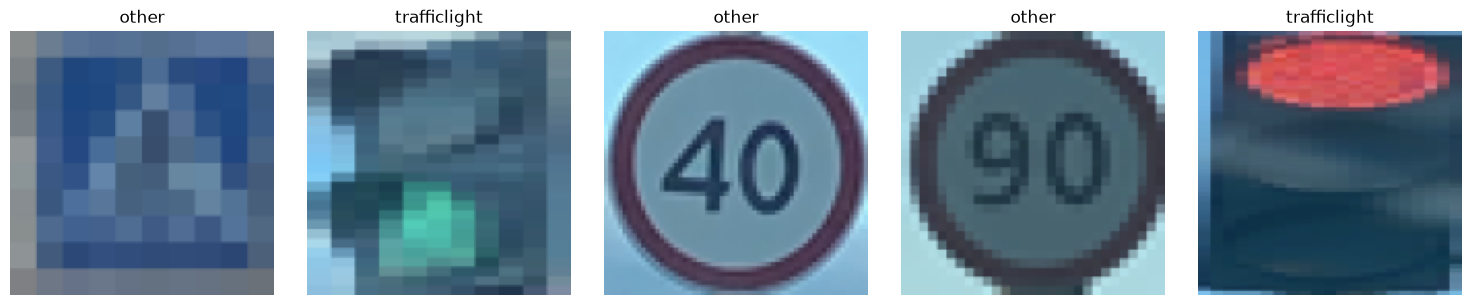

In [7]:
# Visualize a few prepared samples
fig, axes = plt.subplots(1, 5, figsize=(15, 3))

sample_indices = np.random.choice(len(X_data), size=min(5, len(X_data)), replace=False)

for ax, idx in zip(axes, sample_indices):
    ax.imshow(X_data[idx])
    ax.set_title(CLASS_NAMES[y_data[idx]])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [8]:
# Stratified split without requiring scikit-learn
#Train / Validation / Test Split
def stratified_split(X, y, train_ratio=0.70, val_ratio=0.15, seed=42):
    rng = np.random.default_rng(seed)

    train_idx, val_idx, test_idx = [], [], []

    for class_id in np.unique(y):
        indices = np.where(y == class_id)[0]
        rng.shuffle(indices)

        n = len(indices)
        n_train = max(1, int(n * train_ratio))
        n_val = max(1, int(n * val_ratio))

        if n_train + n_val >= n:
            n_val = max(1, n - n_train - 1)

        train_idx.extend(indices[:n_train])
        val_idx.extend(indices[n_train:n_train + n_val])
        test_idx.extend(indices[n_train + n_val:])

    rng.shuffle(train_idx)
    rng.shuffle(val_idx)
    rng.shuffle(test_idx)

    return (
        X[train_idx], y[train_idx],
        X[val_idx], y[val_idx],
        X[test_idx], y[test_idx]
    )

X_train, y_train, X_val, y_val, X_test, y_test = stratified_split(
    X_data, y_data, train_ratio=0.70, val_ratio=0.15, seed=SEED
)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)


Train: (869, 128, 128, 3) (869,)
Validation: (185, 128, 128, 3) (185,)
Test: (190, 128, 128, 3) (190,)


In [9]:
# Convert integer labels to one-hot vectors
num_classes = len(CLASS_NAMES)

y_train_cat = tf.keras.utils.to_categorical(y_train, num_classes)
y_val_cat = tf.keras.utils.to_categorical(y_val, num_classes)
y_test_cat = tf.keras.utils.to_categorical(y_test, num_classes)

print("Number of classes:", num_classes)


Number of classes: 3


In [10]:
#Build and Train the CNN
model = Sequential([
    Input(shape=(*IMG_SIZE, 3)),
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.30),
    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,392,707 (28.20 MB)

 Trainable params: 7,392,707 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
checkpoint_dir = "training_checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

checkpoint_path = os.path.join(checkpoint_dir, "best_model.weights.h5")

callbacks = [
    ModelCheckpoint(
        checkpoint_path,
        monitor="val_accuracy",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        patience=3,
        restore_best_weights=True,
        verbose=1
    )
]

history = model.fit(
    X_train,
    y_train_cat,
    validation_data=(X_val, y_val_cat),
    epochs=15,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 0.8055 - loss: 0.7404
Epoch 1: val_accuracy improved from None to 0.93514, saving model to training_checkpoints\best_model.weights.h5

Epoch 1: finished saving model to training_checkpoints\best_model.weights.h5
28/28 ━━━━━━━━━━━━━━━━━━━━ 9s 211ms/step - accuracy: 0.8055 - loss: 0.7404 - val_accuracy: 0.9351 - val_loss: 0.1969
Epoch 2/15
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.9586 - loss: 0.1489
Epoch 2: val_accuracy improved from 0.93514 to 0.94595, saving model to training_checkpoints\best_model.weights.h5

Epoch 2: finished saving model to training_checkpoints\best_model.weights.h5
28/28 ━━━━━━━━━━━━━━━━━━━━ 10s 206ms/step - accuracy: 0.9586 - loss: 0.1489 - val_accuracy: 0.9459 - val_loss: 0.1488
Epoch 3/15
27/28 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - accuracy: 0.9757 - loss: 0.0757
Epoch 3: val_accuracy improved from 0.94595 to 0.96757, saving model to training_checkpoints\best_model.weights.h5

Epoch 3:

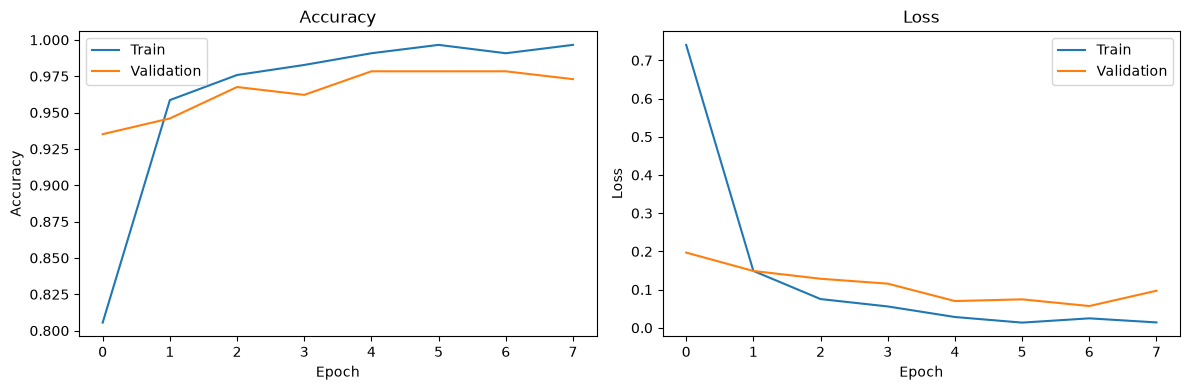

In [12]:
# Plot training history
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [13]:
# Final Evaluation on Unseen Test Data
test_loss, test_accuracy = model.evaluate(X_test, y_test_cat, verbose=0)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")


Test loss: 0.0846
Test accuracy: 0.9789 (97.89%)


In [14]:
# Restore the Best Saved Weights
restored_model = Sequential([
    Input(shape=(*IMG_SIZE, 3)),
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.30),
    Dense(num_classes, activation="softmax")
])

restored_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

restored_model.load_weights(checkpoint_path)

restored_loss, restored_accuracy = restored_model.evaluate(
    X_test, y_test_cat, verbose=0
)

print(f"Restored model test accuracy: {restored_accuracy * 100:.2f}%")


c:\Users\Pragna Parthasarathy\.venv\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_1', because it has 2 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(store)


Restored model test accuracy: 97.89%


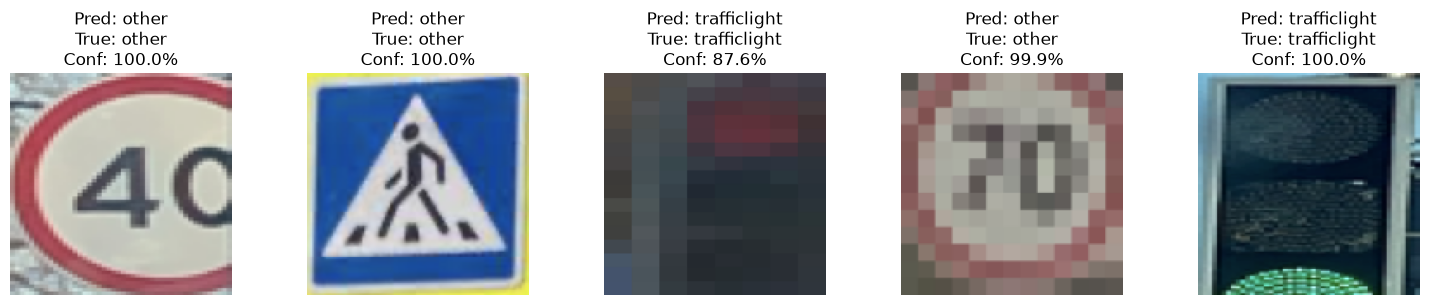

In [15]:
#Visualize Predictions
rng = np.random.default_rng(SEED)
sample_indices = rng.choice(len(X_test), size=min(5, len(X_test)), replace=False)

fig, axes = plt.subplots(1, len(sample_indices), figsize=(15, 3))

if len(sample_indices) == 1:
    axes = [axes]

for ax, idx in zip(axes, sample_indices):
    sample_img = X_test[idx]
    true_id = y_test[idx]

    probabilities = restored_model.predict(
        sample_img[np.newaxis, ...], verbose=0
    )[0]
    predicted_id = int(np.argmax(probabilities))
    confidence = float(np.max(probabilities)) * 100

    ax.imshow(sample_img)
    ax.set_title(
        f"Pred: {CLASS_NAMES[predicted_id]}\n"
        f"True: {CLASS_NAMES[true_id]}\n"
        f"Conf: {confidence:.1f}%"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


In [16]:
#Save the Final Model
model_path = "road_sign_classifier.keras"
restored_model.save(model_path)
print("Model saved to:", model_path)


Model saved to: road_sign_classifier.keras
